In [1]:
import numpy as np
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import os
import glob
from contextlib import contextmanager

In [2]:
if "get_ipython" not in globals() or "get_ipython" in globals() and get_ipython().__class__.__name__ == "TerminalInteractiveShell":
    matplotlib.use("Agg")
    plt.rcParams.update({"figure.dpi": 200})

def plot(figsize=(6.4, 4.8), **kwargs):
    assert DATA_SUBSET != "test"

    plt.gcf().set_size_inches(*figsize)
    if "get_ipython" not in globals() or get_ipython().__class__.__name__ == "TerminalInteractiveShell":
        plt.savefig("a.png", **kwargs)
        plt.clf()
        plt.cla()
    else:
        plt.show()
    plt.close()

def dbg(x):
    print(x)
    return x

# https://stackoverflow.com/a/17511341
def ceildiv(a, b):
    return -(a // -b)

def nplots(n, cols, tight=None, figsize=None):
    if DATA_SUBSET == "test":
        return None

    rows = ceildiv(n, cols)
    figsize=figsize if figsize is not None else (6 * cols, 4 * rows)

    fig, axes = plt.subplots(rows, cols, figsize=figsize)

    for i, ax in enumerate(axes.flatten() if n != 1 else [axes]):
        if i >= n:
            fig.delaxes(ax)
            continue

        yield i, ax

    if tight != False and (n != 1 or tight == True):
        plt.tight_layout()

    plot(figsize=figsize)

@contextmanager
def oneplot(tight=None, figsize=None):
    if DATA_SUBSET == "test":
        return None

    for _, ax in nplots(1, 1, tight=tight, figsize=figsize):
        yield ax

sample_prev_df=None
sample_prev_n=None
sample_ret=None

def sample(df, n=400_000):
    global sample_prev_df
    global sample_prev_n
    global sample_ret

    if sample_prev_df is df and n == sample_prev_n:
        return sample_ret

    sample_ret = None
    sample_prev_df = df
    sample_prev_n = n

    return (sample_ret := df.sample(n, random_state=217, replace=False))

In [3]:
def load_clean(pat):
    return pd.concat([
        pd.read_csv(
            dbg(name),
            dtype=dict(
                VendorID=int,
                passenger_count=float,
                trip_distance=float,
                RatecodeID="category",
                # has NAs, but we're unlikely to use this column so
                # don't drop it
                store_and_fwd_flag="boolean",
                PULocationID="category",
                DOLocationID="category",
                payment_type=int,
                fare_amount=float,
                extra=float,
                mta_tax=float,
                tip_amount=float,
                tolls_amount=float,
                improvement_surcharge=float,
                total_amount=float,
                congestion_surcharge=float,
                Airport_fee=float,
                duration_hours=float,
                avg_speed_mph=float,
                fare_per_hour=float,
            ),
            parse_dates=[
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
            ],
        )
        for name in sorted(glob.glob(f"../dataset-clean/{pat}"))
    ], ignore_index=True)

In [4]:
# DATA_SUBSET = "sample"
DATA_SUBSET = "train"

# NOTE: **DO NOT USE FOR GENERATING GRAPHS**
# This is only allowed here so that the actual data cleaning does not
# have to be copied
# DATA_SUBSET = "test"

rides = load_clean(f"{DATA_SUBSET}_*")

../dataset-clean/train_00.csv
../dataset-clean/train_01.csv
../dataset-clean/train_02.csv
../dataset-clean/train_03.csv
../dataset-clean/train_04.csv
../dataset-clean/train_05.csv
../dataset-clean/train_06.csv
../dataset-clean/train_07.csv
../dataset-clean/train_08.csv
../dataset-clean/train_09.csv
../dataset-clean/train_10.csv
../dataset-clean/train_11.csv
../dataset-clean/train_12.csv
../dataset-clean/train_13.csv
../dataset-clean/train_14.csv


In [5]:
rides.shape

(26593768, 22)

In [6]:
rides.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26593768 entries, 0 to 26593767
Data columns (total 22 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[ns]
 2   tpep_dropoff_datetime  datetime64[ns]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             object        
 6   store_and_fwd_flag     boolean       
 7   PULocationID           object        
 8   DOLocationID           object        
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee         

In [7]:
rides_feat = rides.assign(
    pickup_hour = lambda x: x["tpep_pickup_datetime"].dt.floor("1h"),
    pickup_hour_of_day = lambda x:
        x["tpep_pickup_datetime"].dt.hour +
        (x["tpep_pickup_datetime"].dt.minute / 60),
    # monday = 0
    pickup_day_of_week = lambda x:
        (x["tpep_pickup_datetime"].dt.day_of_week) +
        (x["tpep_pickup_datetime"].dt.hour / 24) +
        (x["tpep_pickup_datetime"].dt.minute / (60 * 24)),
    ratecode_is_airport = lambda x: x["RatecodeID"].isin(["2", "3"]),
    # total amount includes extra surcharges/fees => stronger patterns tip %
    tip_ratio = lambda x: (x["tip_amount"] / (x["total_amount"] - x["tip_amount"])).fillna(0),
)

# Analysis of individual trips

* weak seasonal patterns
* strong weekday patterns
  * many cabs into early morning on weekends
  * slight dropoff in late mornings on weekends

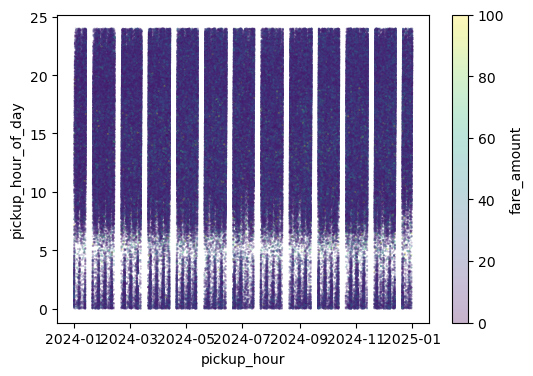

In [8]:
with oneplot() as ax:
    sample(rides_feat).plot(
        kind="scatter",
        x="pickup_hour",
        y="pickup_hour_of_day",
        c="fare_amount",
        cmap="viridis",
        s=0.2,
        alpha=0.3,
        ax=ax,
    )

* strong distributions for location
* mostly short trips

VendorID
tpep_pickup_datetime
tpep_dropoff_datetime
passenger_count
trip_distance
RatecodeID
store_and_fwd_flag
PULocationID
DOLocationID
payment_type
fare_amount
extra
mta_tax
tip_amount
tolls_amount
improvement_surcharge
total_amount
congestion_surcharge
Airport_fee
duration_hours
avg_speed_mph
fare_per_hour
pickup_hour
pickup_hour_of_day
pickup_day_of_week
ratecode_is_airport
tip_ratio


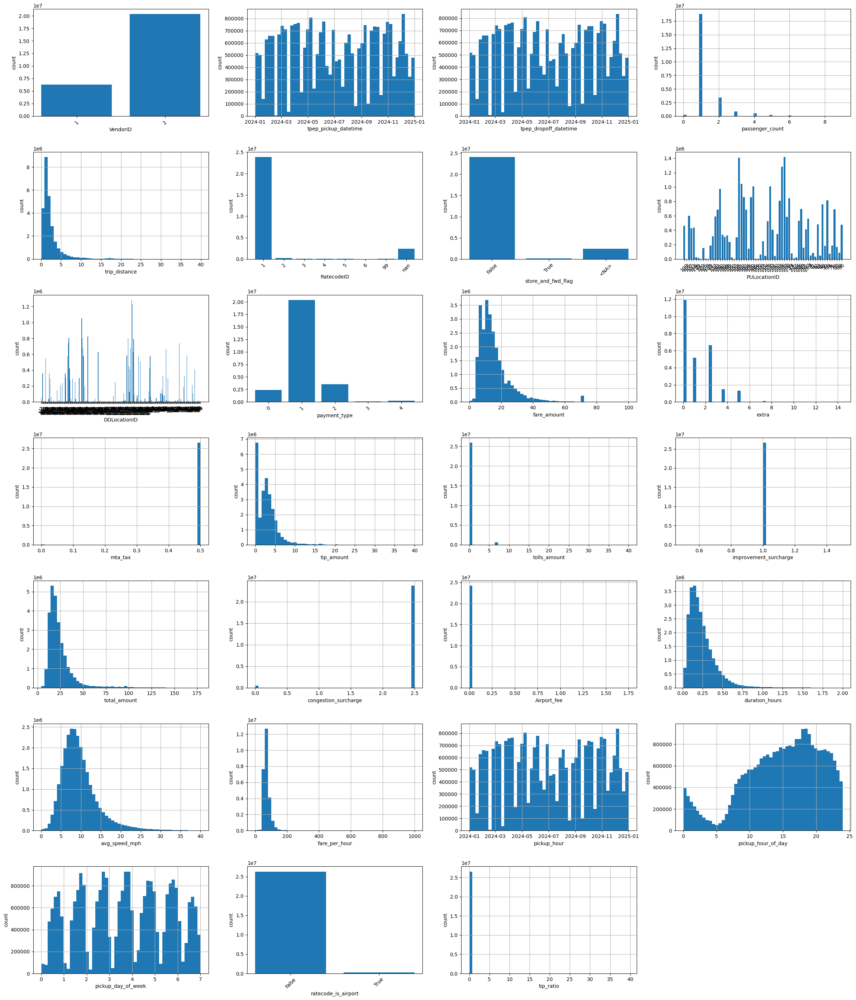

In [9]:
for i, ax in nplots(len(rides_feat.columns), 4):
    col = dbg(rides_feat.columns[i])
    # https://stackoverflow.com/a/43215603/7097552
    dtype = rides_feat.dtypes[col]
    if dtype == float or (
        isinstance(dtype, np.dtype) and np.issubdtype(dtype, np.datetime64)
    ):
        rides_feat[col].hist(ax=ax, bins=50)
        ax.set_xlabel(col)
        ax.set_ylabel("count")
    else:
        counts = rides_feat[col].value_counts(dropna=False).sort_index()
        ax.bar(counts.index.astype(str), counts.values)
        ax.set_xlabel(col)
        ax.set_ylabel("count")
        ax.tick_params(axis="x", rotation=45)

## Fare amount correlations

Categorical
* `RatecodeID` has some indicators
  * 2 and 3, airport trips are generally higher
  * 1 has a relatively tight distribution
* `PULocation` is mostly the same, some minor outliers

VendorID
RatecodeID
store_and_fwd_flag
PULocationID
DOLocationID
payment_type
ratecode_is_airport


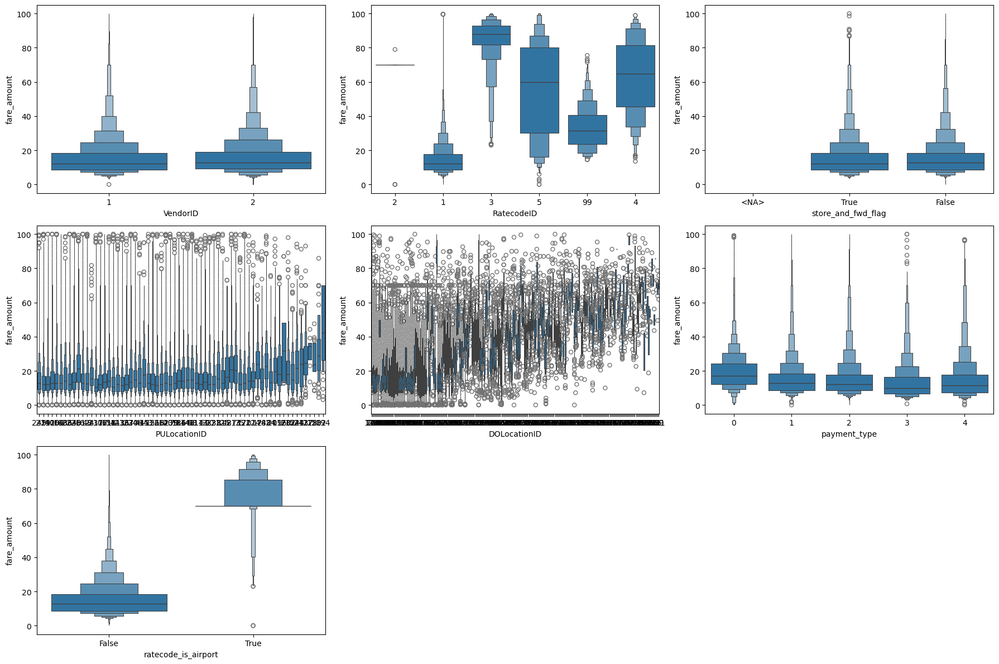

In [10]:
cats = [
    col
    for col, dtype in dict(rides_feat.dtypes).items()
    if not (dtype == float or (
        isinstance(dtype, np.dtype) and np.issubdtype(dtype, np.datetime64)
    ))
]

for i, ax in nplots(len(cats), 3):
    sns.boxenplot(
        ax=ax,
        data=sample(rides_feat, n=1_000_000),
        x=dbg(cats[i]),
        y="fare_amount",
        order=[pd.NA, True, False] if isinstance(rides_feat.dtypes[cats[i]], pd.BooleanDtype) else None,
    )
    ax.set_xlabel(cats[i])
    ax.set_ylabel("fare_amount")

What every cab driver wants to know

* pickups from 120 and 194 have outlyingly large tips
* but the ratio is generaly in line with the other locations, 194 has
  a fatter tail in the high end
* tip ratios mostly have the same IQR upper bound (20%, US tip is usually 15%
  I guess NYC prices _shrug_), but varying lower bounds
  * 236, 237, 141, 142, 262 - upper east side (gossip girl, sex and the city, american psycho, some of
    the great gatsby, etc. )
  * 161, 162, 163 - midtown (empire state building, bloomies, tiffany's (of breakfast fame, though
                    the rest of the story is in the upper east side))
  * 162, 229 - turtle bay (UN HQ)
* A few zones have low upper bounds
  * 42, 116, 127, 243, 255 - harlem and northern manhattan (of renaissance and shake fame, redlined)

Yea... Doesn't take a CS MSc student to figure this out

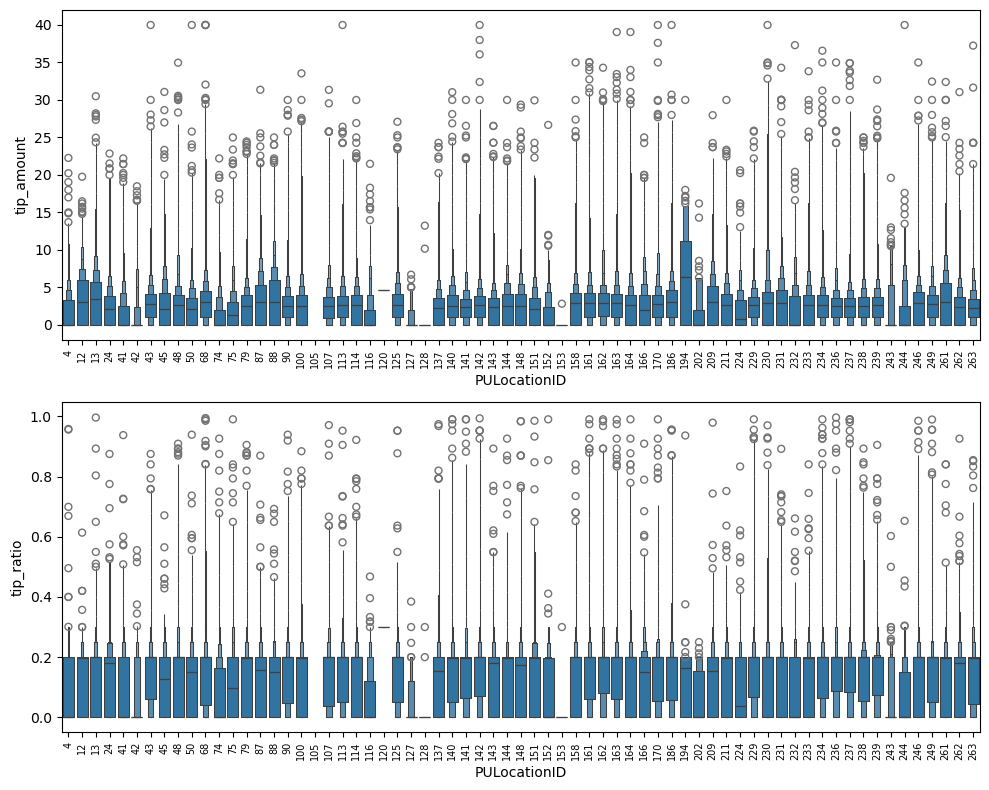

In [11]:
for i, ax in nplots(2, 1, figsize=(10, 8)):
    sns.boxenplot(
        ax=ax,
        data=sample(rides_feat[rides_feat["tip_ratio"] < 1], n=1_000_000),
        x="PULocationID",
        y=["tip_amount", "tip_ratio"][i],
        order=sorted(rides_feat["PULocationID"].unique(), key=int),
    )
    ax.tick_params(axis="x", rotation=90, labelsize=7)

Numerical
*

tip_ratio
fare_amount
fare_amount
total_amount
total_amount
total_amount
trip_distance
trip_distance
trip_distance
trip_distance
duration_hours
duration_hours
duration_hours
duration_hours
duration_hours
avg_speed_mph
avg_speed_mph
avg_speed_mph
avg_speed_mph
avg_speed_mph
avg_speed_mph
fare_per_hour
fare_per_hour
fare_per_hour
fare_per_hour
fare_per_hour
fare_per_hour
fare_per_hour
pickup_hour_of_day
pickup_hour_of_day
pickup_hour_of_day
pickup_hour_of_day
pickup_hour_of_day
pickup_hour_of_day
pickup_hour_of_day
pickup_hour_of_day
pickup_day_of_week
pickup_day_of_week
pickup_day_of_week
pickup_day_of_week
pickup_day_of_week
pickup_day_of_week
pickup_day_of_week
pickup_day_of_week
pickup_day_of_week


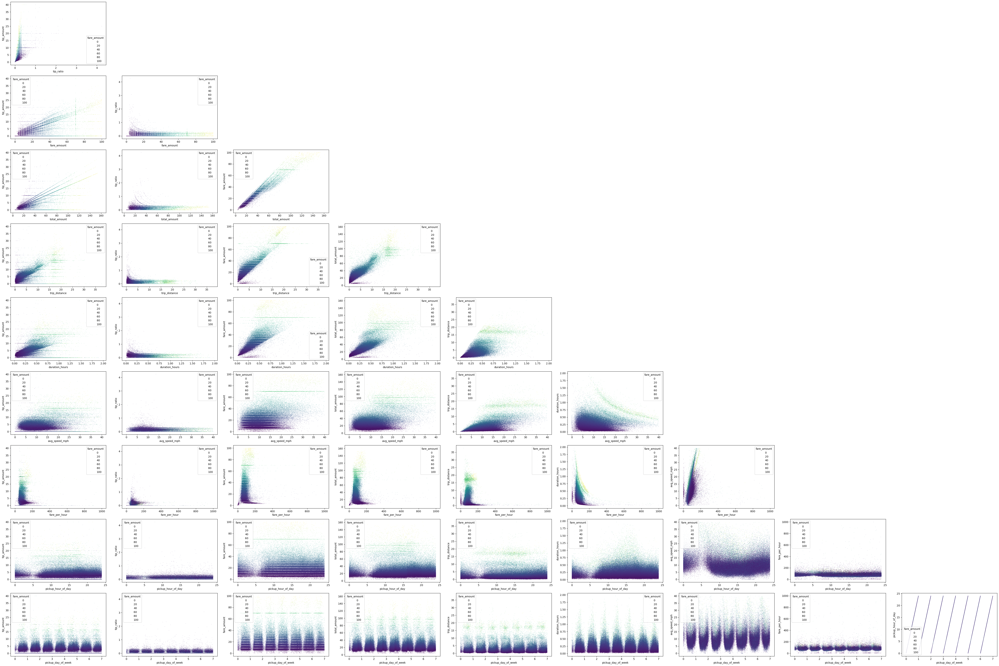

In [12]:
nums = [
    col
    for col, dtype in dict(rides_feat.dtypes).items()
    if (dtype == float or (
        isinstance(dtype, np.dtype) and np.issubdtype(dtype, np.datetime64)
    ))
]

nums = [
    "tip_amount",
    "tip_ratio",
    "fare_amount",
    "total_amount",
    "trip_distance",
    "duration_hours",
    "avg_speed_mph",
    "fare_per_hour",
    "pickup_hour_of_day",
    "pickup_day_of_week",
]

for i, ax in nplots((len(nums) - 1) ** 2, len(nums) - 1):
    col = i % (len(nums) - 1)
    row = (i // (len(nums) - 1)) + 1

    if col >= row:
       ax.remove()
       continue

    sns.scatterplot(
        ax=ax,
        data=sample(rides_feat, 200_000),
        x=dbg(nums[row]),
        y=nums[col],
        hue=sample(rides_feat, 200_000)["fare_amount"],
        s=0.5,
        linewidth=0,
        palette="viridis",
    )
    ax.set_xlabel(nums[row])
    ax.set_ylabel(nums[col])

* aiport trips happen between 5 and 10
* trip distance has clusters
  * main cluster thins out at 5am
  * there's a secondary cluster, looks like airports based on color and time
  * there's a barely distingushable cluster around the middle of the day
    with distance of 10 miles
* duration spikes in the afternoon until 8pm with a small bump after
* weekends have slightly less variance in distance and time?
* upper quartile of trips take less time on weekends
* there's a maximum speed
  * this is imposed by by us (40 mph)
  * for a given distance, there's a long tail of how long the trip takes
* higher distance and duration trips cost more
* distance has stronger corrrelation
* the distance/fare amount graph has two modes at the high end
* distance vs fare per hour, in the bigger mode has an interesting relationship:
  * **for a fixed _short_ distance, fare-per-hour is inversely related to fare amount**
  * for long distance trips, fare-per-hour is directly related to fare amount
  * waiting in traffic yeilds higher fares, but they are not time efficient
* airport trips are generally more time efficient than other long-distance trips
* straight lines for tips means most people pick round numbers or round percentages

('pickup_hour_of_day', 'fare_amount')
('pickup_hour_of_day', 'trip_distance')
('pickup_hour_of_day', 'duration_hours')
('pickup_day_of_week', 'fare_amount')
('pickup_day_of_week', 'trip_distance')
('pickup_day_of_week', 'duration_hours')
('duration_hours', 'trip_distance')
('duration_hours', 'fare_amount')
('trip_distance', 'fare_amount')
('fare_amount', 'fare_per_hour')
('duration_hours', 'fare_per_hour')
('trip_distance', 'fare_per_hour')
('tip_amount', 'tip_ratio')


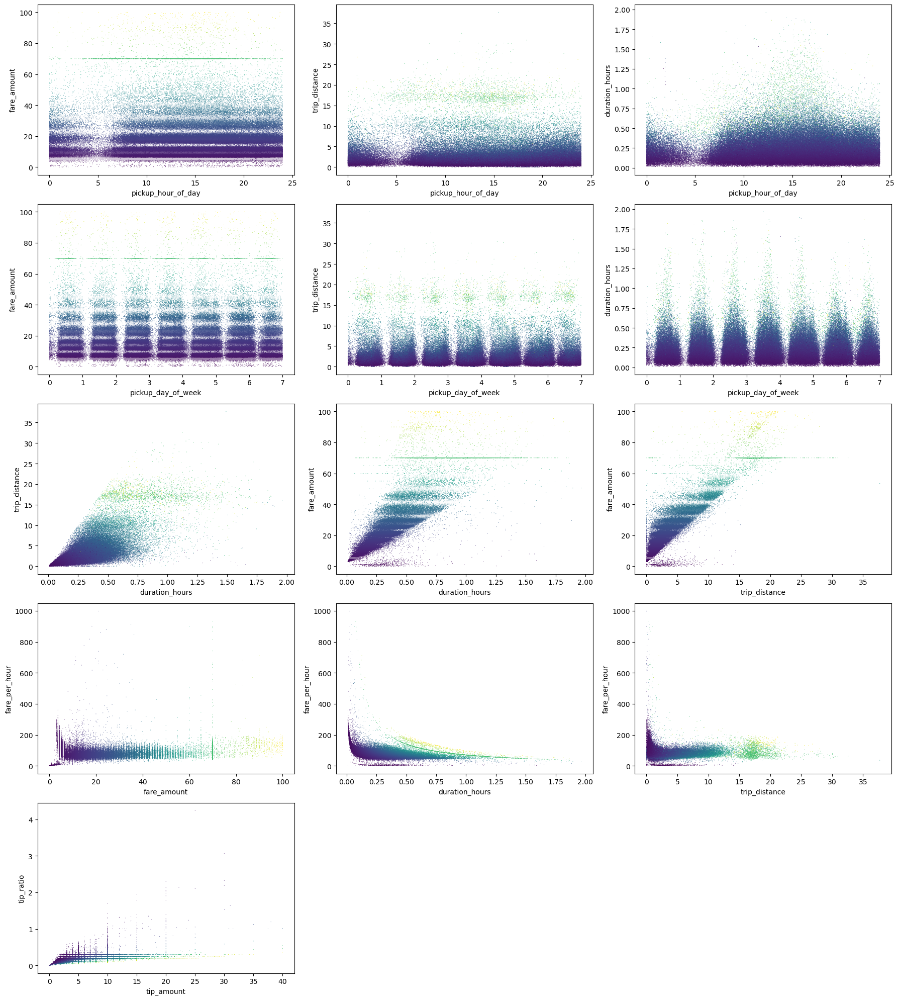

In [13]:
nums_neat = [
    # using total fare to avoid aliasing, but also
    # shows the congestion surcharge
    ("pickup_hour_of_day", "fare_amount"),
    ("pickup_hour_of_day", "trip_distance"),
    ("pickup_hour_of_day", "duration_hours"),

    ("pickup_day_of_week", "fare_amount"),
    ("pickup_day_of_week", "trip_distance"),
    ("pickup_day_of_week", "duration_hours"),

    ("duration_hours", "trip_distance"),
    ("duration_hours", "fare_amount"),
    ("trip_distance", "fare_amount"),

    ("fare_amount", "fare_per_hour"),
    # these variables are dependent
    # but have value together: longer trips with the same fare per hour
    # are more valuable as it guarantees high revenue vs waiting for the
    # next trip
    ("duration_hours", "fare_per_hour"),
    ("trip_distance", "fare_per_hour"),

    ("tip_amount", "tip_ratio"),
]

for (i, ax), (x, y) in zip(
    nplots(len(nums_neat), 3),
    nums_neat,
):
    dbg((x, y))
    sns.scatterplot(
        ax=ax,
        data=sample(rides_feat, 200_000),
        x=x,
        y=y,
        hue=sample(rides_feat, 200_000)["fare_amount"],
        s=0.5,
        linewidth=0,
        palette="viridis",
        legend=False,
    )
    ax.set_xlabel(x)
    ax.set_ylabel(y)

* subset of zones show 3 modes - 230, 48, 170, 16{1,2,3,4}, 233, 236
  * they're all around midtown and 236 is upper east side

['4', '12', '13', '24', '41', '42']
['43', '45', '48', '50', '68', '74']
['75', '79', '87', '88', '90', '100']
['105', '107', '113', '114', '116', '120']
['125', '127', '128', '137', '140', '141']
['142', '143', '144', '148', '151', '152']
['153', '158', '161', '162', '163', '164']
['166', '170', '186', '194', '202', '209']
['211', '224', '229', '230', '231', '232']
['233', '234', '236', '237', '238', '239']
['243', '244', '246', '249', '261', '262']
['263']


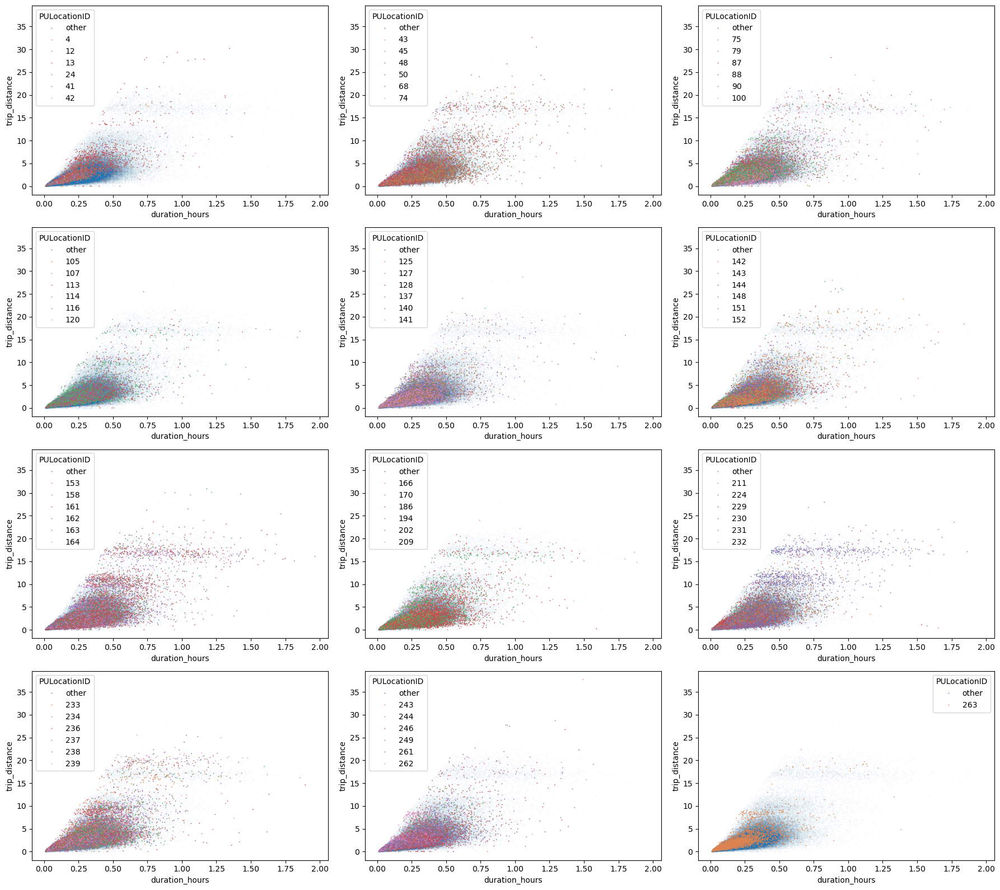

In [14]:
zones = sorted(rides_feat["PULocationID"].unique(), key=int)
zone_chunks = [
    zones[i:i+6]
    for i in range(0, len(zones), 6)
]

for (i, ax), chunk in zip(
    nplots(len(zone_chunks), 3),
    zone_chunks
):
    dbg(chunk)
    samp = sample(rides_feat, 200_000)

    sns.scatterplot(
        ax=ax,
        data=samp[~samp["PULocationID"].isin(chunk)],
        x="duration_hours",
        y="trip_distance",
        s=2,
        alpha=0.04,
        linewidth=0,
    )
    sns.scatterplot(
        ax=ax,
        data=samp[samp["PULocationID"].isin(chunk)],
        x="duration_hours",
        y="trip_distance",
        hue=samp["PULocationID"],
        hue_order= ["other"] + chunk,
        s=2,
        alpha=0.8,
        linewidth=0,
        palette="deep",
    )
    ax.set_xlabel("duration_hours")
    ax.set_ylabel("trip_distance")

Though the histograms don't show anything particularly special about this
* slightly more aiport trips
* pickup hour of day is more skewed to late afternoon
* pickup day of the week is biased to early in the week

VendorID
tpep_pickup_datetime
tpep_dropoff_datetime
passenger_count
trip_distance
RatecodeID
store_and_fwd_flag
PULocationID
DOLocationID
payment_type
fare_amount
extra
mta_tax
tip_amount
tolls_amount
improvement_surcharge
total_amount
congestion_surcharge
Airport_fee
duration_hours
avg_speed_mph
fare_per_hour
pickup_hour
pickup_hour_of_day
pickup_day_of_week
ratecode_is_airport
tip_ratio


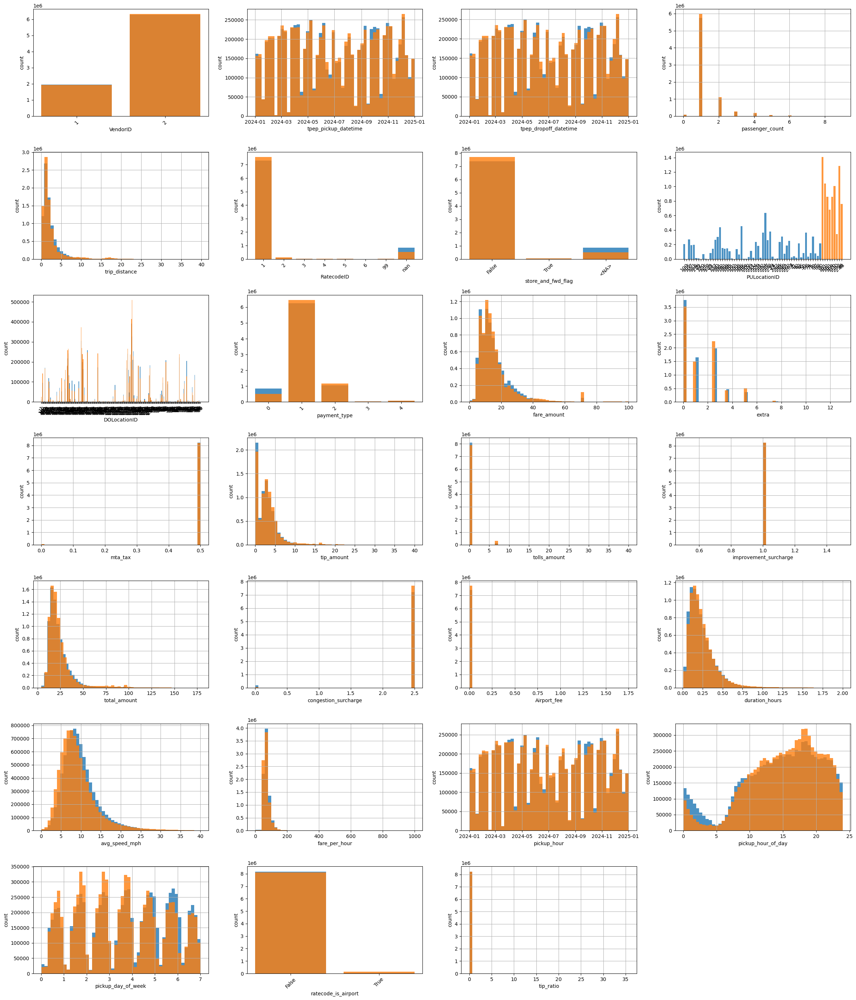

In [15]:
trimodal = list(map(str, sorted([230, 48, 170, 161, 162, 163, 164, 233, 236])))

samp_filt = rides_feat[rides_feat["PULocationID"].isin(trimodal)].reset_index(drop=True)
# normalize the comparison (hacky)
samp = sample(rides_feat[~rides_feat["PULocationID"].isin(trimodal)].reset_index(drop=True), len(samp_filt))

for i, ax in nplots(len(rides_feat.columns), 4):
    col = dbg(rides_feat.columns[i])
    # https://stackoverflow.com/a/43215603/7097552
    dtype = rides_feat.dtypes[col]
    if dtype == float or (
        isinstance(dtype, np.dtype) and np.issubdtype(dtype, np.datetime64)
    ):
        samp[col].hist(ax=ax, bins=50, alpha=0.8)
        samp_filt[col].hist(ax=ax, bins=50, alpha=0.8)
        ax.set_xlabel(col)
        ax.set_ylabel("count")
    else:
        counts = samp[col].value_counts(dropna=False).sort_index()
        ax.bar(counts.index.astype(str), counts.values, alpha=0.8)
        counts = samp_filt[col].value_counts(dropna=False).sort_index()
        ax.bar(counts.index.astype(str), counts.values, alpha=0.8)

        ax.set_xlabel(col)
        ax.set_ylabel("count")
        ax.tick_params(axis="x", rotation=45)

* there exists fare amount frontiers in time and space. That is, for a
  trip with a particular distance or duration, there (roughly) exists
  a maximum fare that can be made
* generally, trips with higher speeds have higher per-hour fares
* trips with higher per-hour fares are generally shorter (in both
  distance and space) and cheaper
* as we saw previously, airport fares are fixed at $70
  * they are generally longer disntace and take more time
  * they sit above the distance frontier, but below the duration
    frontier
  * for a given duration, airport trips give the best return per-hour
  * one can conclude they reduce risk (of looking for new trips) while
    having a good yield
  * however, it might take a long time to find a trip at the airport
    to return into manhattan, this may erase any other gains
  * the longer distance (3x the mass of trips between 0-5) means higher fuel costs

('fare_amount', 'duration_hours', 'ratecode_is_airport')
('fare_amount', 'duration_hours', 'fare_amount')
('fare_amount', 'trip_distance', 'ratecode_is_airport')
('fare_amount', 'trip_distance', 'fare_amount')
('fare_per_hour', 'trip_distance', 'ratecode_is_airport')
('fare_per_hour', 'trip_distance', 'fare_amount')
('fare_per_hour', 'duration_hours', 'ratecode_is_airport')
('fare_per_hour', 'duration_hours', 'fare_amount')


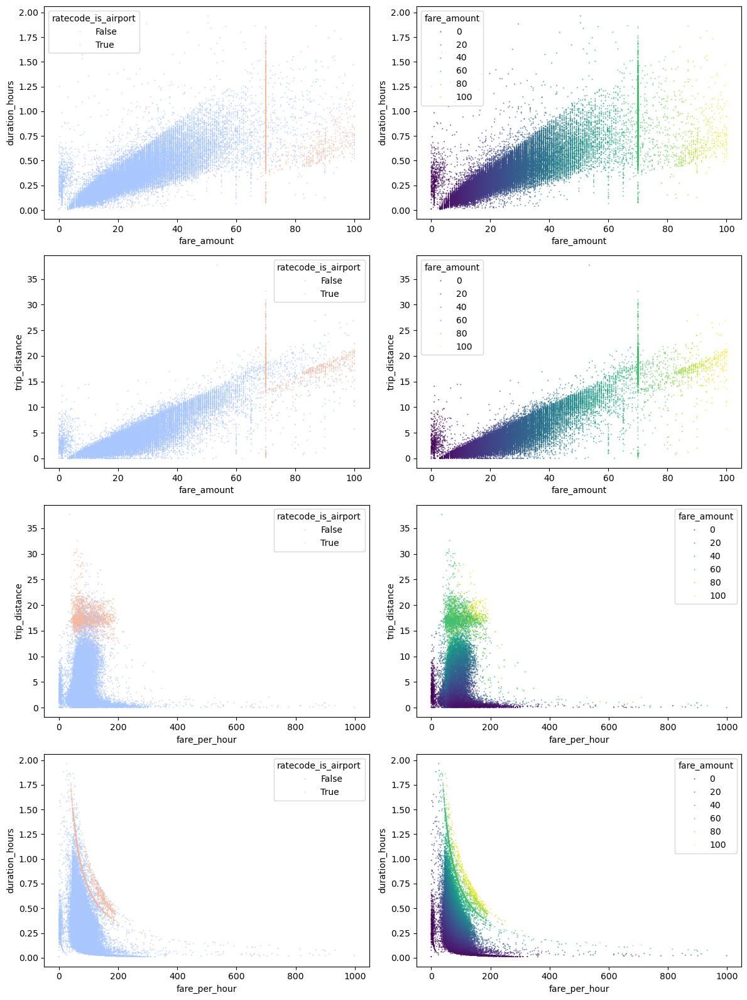

In [22]:
interest = [
    ("fare_amount", "duration_hours", "ratecode_is_airport"),
    ("fare_amount", "duration_hours", "fare_amount"),
    ("fare_amount", "trip_distance", "ratecode_is_airport"),
    ("fare_amount", "trip_distance", "fare_amount"),
    ("fare_per_hour", "trip_distance", "ratecode_is_airport"),
    ("fare_per_hour", "trip_distance", "fare_amount"),
    ("fare_per_hour", "duration_hours", "ratecode_is_airport"),
    ("fare_per_hour", "duration_hours", "fare_amount"),
]

for i, ax in nplots(len(interest), 2):
    x, y, hue = dbg(interest[i])
    sns.scatterplot(
        ax=ax,
        data=sample(rides_feat, 200_000),
        x=x,
        y=y,
        hue=sample(rides_feat, 200_000)[hue],
        s=2,
        alpha=0.7,
        linewidth=0,
        palette="viridis" if hue == "fare_amount" else "coolwarm",
    )
    ax.set_xlabel(x)
    ax.set_ylabel(y)

We have a problem, a lot of our features here are loosely correlated

https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html#handling-multicollinear-features

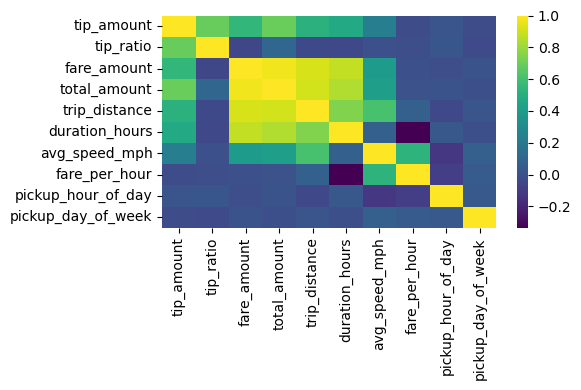

In [23]:
with oneplot(tight=True) as ax:
    sns.heatmap(
        sample(rides_feat[nums]).corr(),
        cmap="viridis",
    )

In [24]:
# xval some RFs to find feature importances

from sklearn.model_selection import cross_validate, ShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor

Confirm relationships with rfs

* trip distance and duration can be used to predict fare amount
  * the high variance in these means the individual trees will pick
    one of them, this makes sense as they're loosely correlated
* drop off, pick up, day of the week, and ratecode predict distance
* same for duration, but pick up and day of week are slightly more
  important; also avg speed is useful, this makes sense as it
  relates to traffic
* drop offs are probably helpful, but it's not obvious how
  to encode this in aggregation
  * ohe the top N from the previous zone/hour window would lead to
    `N * card(DOLocationID)` features
  * maybe only consider a subset of the drop off locations, but not
    obvious how to pick these

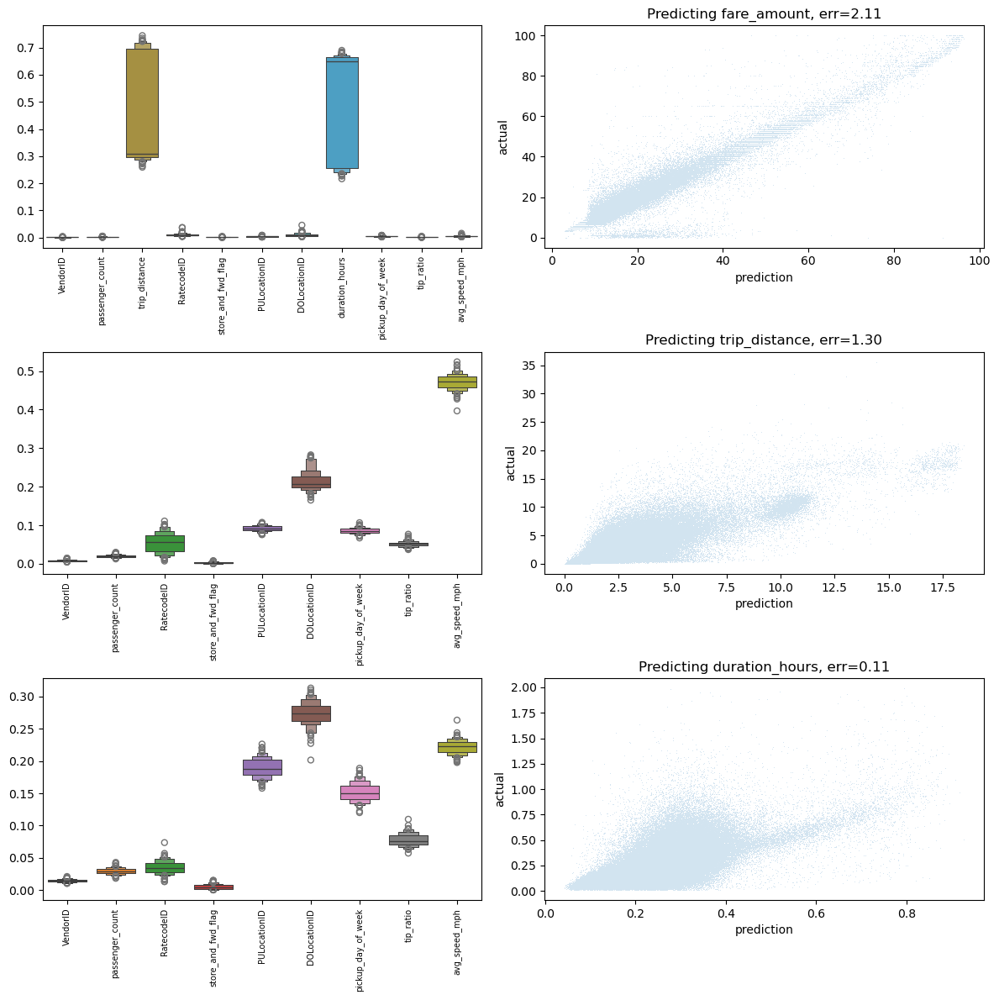

In [25]:
import itertools as it

# find feature importances using random forests
def rf_importance(df, xcols, target):
    assert target not in xcols

    rf = RandomForestRegressor(
        n_estimators=100,
        max_samples=10_000,
        random_state=271,
        # verbose=10,
        n_jobs=-1,
    )
    rf.fit(
        df[xcols],
        df[target],
    )

    importances = pd.DataFrame(
        [
            tree.feature_importances_
            for tree in rf.estimators_
        ],
        columns=xcols,
    )

    df_sample = sample(df)
    pred = rf.predict(df_sample[xcols])
    actual = df_sample[target]

    return importances, pred, actual

base_ind = [
    "VendorID",
    "passenger_count",
    "trip_distance",
    "RatecodeID",
    "store_and_fwd_flag",
    "PULocationID",
    "DOLocationID",
    "duration_hours",
    "pickup_day_of_week",
    "tip_ratio",
    "avg_speed_mph",
]

target_corrs = [
    ("fare_amount", []),
    ("trip_distance", ["duration_hours"]),
    ("duration_hours", ["trip_distance"]),
]

for i, ((_, ax1), (_, ax2)) in enumerate(it.batched(nplots(len(target_corrs) * 2, 2), 2)):
    target, corr = target_corrs[i]
    xcols = [x for x in base_ind if x not in corr and x != target]

    importances, pred, actual = rf_importance(
        rides_feat[rides_feat["fare_amount"] != 70],
        xcols,
        target
    )

    sns.boxenplot(
        ax=ax1,
        data=importances,
    )
    ax1.tick_params(axis="x", rotation=90, labelsize=7)

    sns.scatterplot(
        ax=ax2,
        x=pred,
        y=actual,
        s=0.5,
        linewidth=0,
    ),
    ax2.set_xlabel("prediction")
    ax2.set_ylabel("actual")

    err = np.sqrt(mean_squared_error(pred, actual))
    ax2.set_title(f"Predicting {target}, err={err:.2f}")

In [26]:
# # Creating the aggregated dataset
#
# We're concerned with large scale allocation of taxis over
# space and time, with the scales of zones and hours respectively.
# Zones are the finest granularity we have for space. And hours
# is fine grained enough to see (expected) trends throughout the
# day and large enough to make predictions one or more days
# ahead of time.

In [27]:
def group_zone_hour(
    df,
    aggs,
):
    """
    Aggregrate trips into zone-hour statistics

    df : pd.DataFrame
        Trip-level dataframe
    aggs : function, str, list, dict or None
        Argument to pd.DataFrameGroupBy.agg, specify which columsn and
        how aggregation should be done

    Returns:
    pd.DataFrame
        Dataframe with zone-hour and aggregated values
    """
    378798
    586920

    df = (
        df
            .groupby(["PULocationID", "pickup_hour"], observed=True)
            .agg(aggs)
            .reset_index()
    )
    # flaten column names
    df.columns = [(f"cur_{x}_{y}" if y else x) for (x, y) in df.columns]

    return df

def with_lags(
    df,
    feature,
    agg,
    window="2h",
    offsets=["1h"],
):
    agged = df.rename(
        columns=lambda x: x.removeprefix("cur_") if isinstance(x, str) else x,
    ).groupby("PULocationID")[["pickup_hour", feature]].rolling(
        window,
        on="pickup_hour",
    ).agg(agg)

    for offset in offsets:
        df = pd.merge(
            df,
            agged.assign(
                pickup_hour=agged["pickup_hour"] +
                    (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
            ).rename(
                columns=lambda x:
                    f"lag_{feature}-{agg}-{window}-{offset}" if x not in ["PULocationID", "pickup_hour"] else x,
            ),
            how="left",
            on=["PULocationID", "pickup_hour"],
        )

    return df

In [28]:
zone_upper_east = [str(x) for x in [236, 237, 141, 142, 262]]
zone_midtown = [str(x) for x in [161, 162, 163]]
zone_financial = [str(x) for x in [12, 88, 87, 261]]
zone_turtle_bay = [str(x) for x in [162, 229]]
zone_north = [str(x) for x in [42, 116, 127, 243, 255]]

rides_hour = group_zone_hour(
    dbg(pd.concat(
        [
            rides_feat,
            pd.get_dummies(rides_feat["RatecodeID"], prefix="ratecode_is"),
            pd.DataFrame(dict(
                do_is_upper_east=rides_feat["DOLocationID"].isin(zone_upper_east),
                do_is_midtown=rides_feat["DOLocationID"].isin(zone_midtown),
                do_is_financial=rides_feat["DOLocationID"].isin(zone_financial),
                do_is_turtle_bay=rides_feat["DOLocationID"].isin(zone_turtle_bay),
                do_is_north=rides_feat["DOLocationID"].isin(zone_north),
            ))
        ],
        axis=1,
    )),
    dict(
        passenger_count="mean",
        trip_distance=["sum", "mean"],
        # amount without tips or fees
        fare_amount=["sum", "mean"],
        # the following are somewhat fixed fees so the means
        # are losely counts of rides where the fee is charged
        # not much info intrinsically but maybe a patern?
        mta_tax="mean",
        tolls_amount="mean",
        improvement_surcharge="mean",
        congestion_surcharge="mean",
        Airport_fee="mean",
        # total amount including tips and fees
        # * in our case these are "noise" when making predictions
        # * if we really wanted to be vultures we might look at tips
        #   as an indicator of routes where we could charge more
        total_amount=["sum", "mean"],
        tip_amount="mean",
        tip_ratio="mean",
        # probably correlated with demand
        # * count used in this column arbitrarily
        duration_hours=["count", "sum", "mean"],
        avg_speed_mph="mean",
        fare_per_hour="mean",
        ratecode_is_airport=["mean", "count"],

        ratecode_is_1="mean",
        ratecode_is_2="mean",
        ratecode_is_3="mean",
        ratecode_is_4="mean",
        ratecode_is_5="mean",
        ratecode_is_6="mean",
        ratecode_is_99="mean",

        do_is_upper_east="mean",
        do_is_midtown="mean",
        do_is_financial="mean",
        do_is_turtle_bay="mean",
        do_is_north="mean",
    ),
).assign(
    pickup_hour_of_day=lambda x: x["pickup_hour"].dt.hour,
).rename(
    columns=dict(
        cur_duration_hours_count="cur_count",
    )
)

          VendorID tpep_pickup_datetime tpep_dropoff_datetime  \
0                1  2024-01-01 00:00:00   2024-01-01 00:02:49   
1                2  2024-01-01 00:00:02   2024-01-01 00:04:36   
2                2  2024-01-01 00:00:04   2024-01-01 00:22:32   
3                2  2024-01-01 00:00:11   2024-01-01 00:42:33   
4                1  2024-01-01 00:00:11   2024-01-01 00:21:25   
...            ...                  ...                   ...   
26593763         2  2024-12-31 23:59:45   2025-01-01 00:07:32   
26593764         2  2024-12-31 23:59:48   2025-01-01 00:03:20   
26593765         2  2024-12-31 23:59:50   2025-01-01 00:14:40   
26593766         1  2024-12-31 23:59:56   2025-01-01 00:11:07   
26593767         2  2024-12-31 23:59:58   2025-01-01 00:02:53   

          passenger_count  trip_distance RatecodeID  store_and_fwd_flag  \
0                     1.0           0.30          1               False   
1                     2.0           1.57          1               Fal

In [29]:
rides_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 388101 entries, 0 to 388100
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   PULocationID                    388101 non-null  object        
 1   pickup_hour                     388101 non-null  datetime64[ns]
 2   cur_passenger_count_mean        377986 non-null  float64       
 3   cur_trip_distance_sum           388101 non-null  float64       
 4   cur_trip_distance_mean          388101 non-null  float64       
 5   cur_fare_amount_sum             388101 non-null  float64       
 6   cur_fare_amount_mean            388101 non-null  float64       
 7   cur_mta_tax_mean                388101 non-null  float64       
 8   cur_tolls_amount_mean           388101 non-null  float64       
 9   cur_improvement_surcharge_mean  388101 non-null  float64       
 10  cur_congestion_surcharge_mean   377986 non-null  float64

# Correlations to `cur_fare_amount_mean` (revenue)

* count and duration_hours_sum are pretty much the same
  * makes sense! more trips in a zone hour -> more trip hours
  * similar to before, longer trips raise the minimum fare mount
  * however, shorter trips have a higher variance, eg. higher
* duration_hours_mean has structure
* variance in pickup_hour_of_day is high, but has rough patterns
  for mean fare amount
  * early evening rides are cheaper
  * early morning rides have a higher tail

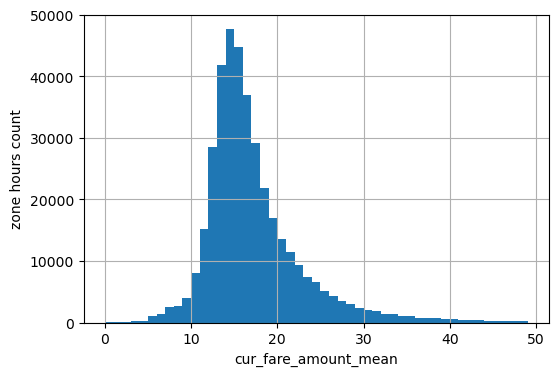

In [30]:
with oneplot() as ax:
    rides_hour["cur_fare_amount_mean"].hist(bins=list(range(0, 50, 1)), ax=ax)
    ax.set_xlabel("cur_fare_amount_mean")
    ax.set_ylabel("zone hours count")

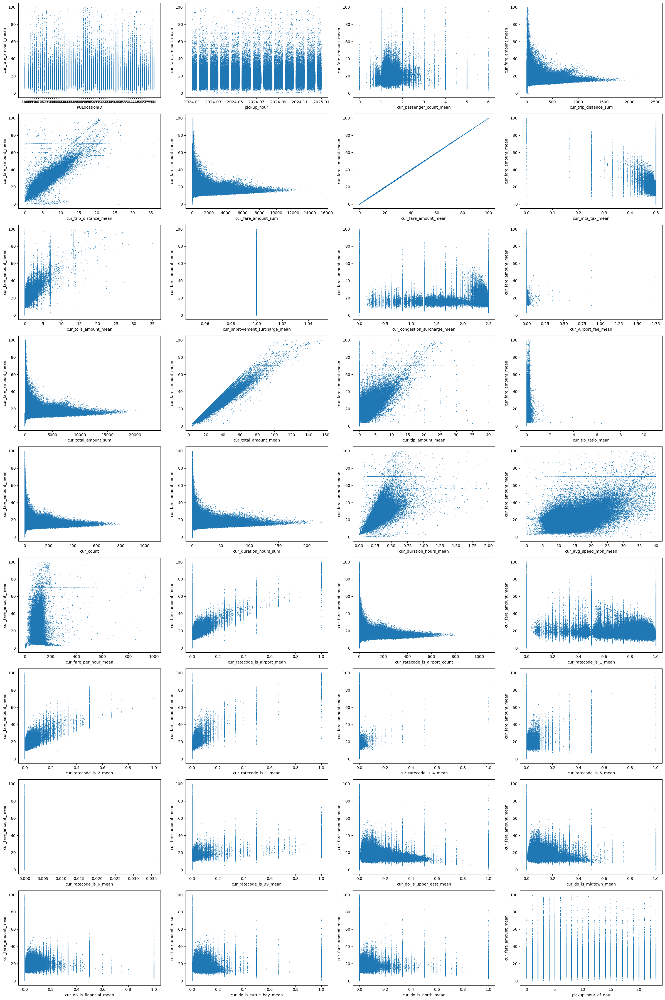

In [31]:
target = "cur_fare_amount_mean"

for i, ax in nplots(len(rides_hour.columns), 4):
    sns.scatterplot(
        ax=ax,
        data=rides_hour,
        x=rides_hour.columns[i],
        y=target,
        s=2,
        linewidth=0,
    )
    ax.set_xlabel(rides_hour.columns[i])
    ax.set_ylabel(target)

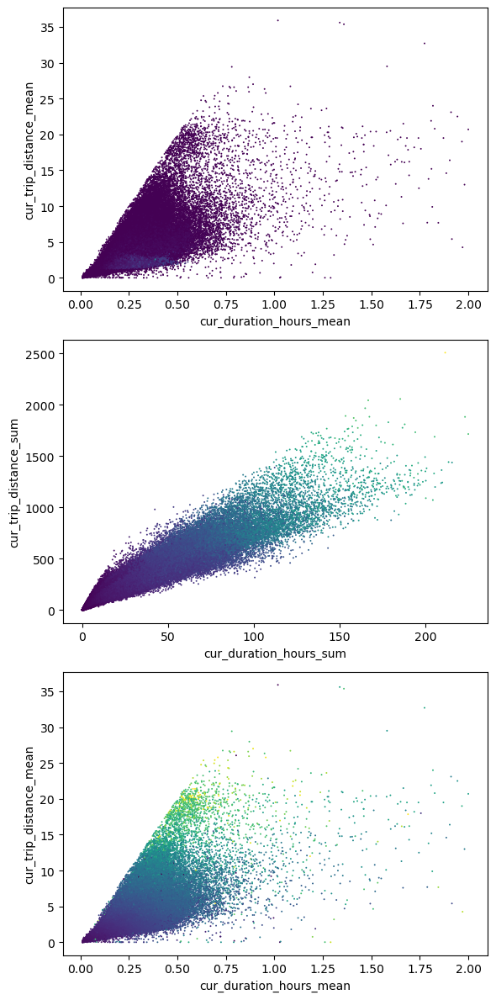

In [32]:
group_corrs = [
    ("cur_duration_hours_mean", "cur_trip_distance_mean", "cur_count"),
    ("cur_duration_hours_sum", "cur_trip_distance_sum", "cur_count"),
    ("cur_duration_hours_mean", "cur_trip_distance_mean", "cur_fare_amount_mean"),
]

for i, ax in nplots(len(group_corrs), 1):
    x, y, c = group_corrs[i]
    sns.scatterplot(
        ax=ax,
        data=rides_hour,
        x=x,
        y=y,
        c=rides_hour[c],
        s=2,
        linewidth=0,
        cmap="viridis",
    )
    ax.set_xlabel(x)
    ax.set_ylabel(y)

# Correlations to `cur_count` (demand)

* firstly, most zone-hours have low samples,
  * this is an issue because it means most rows in the the zone-hour aggregated
    table represent a low "mass" of rides
* as above, strong correlations with all the "*_sum" columns

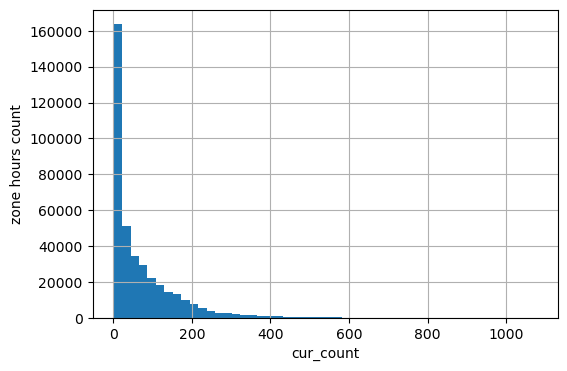

In [33]:
with oneplot() as ax:
    rides_hour["cur_count"].hist(bins=50, ax=ax)
    ax.set_xlabel("cur_count")
    ax.set_ylabel("zone hours count")

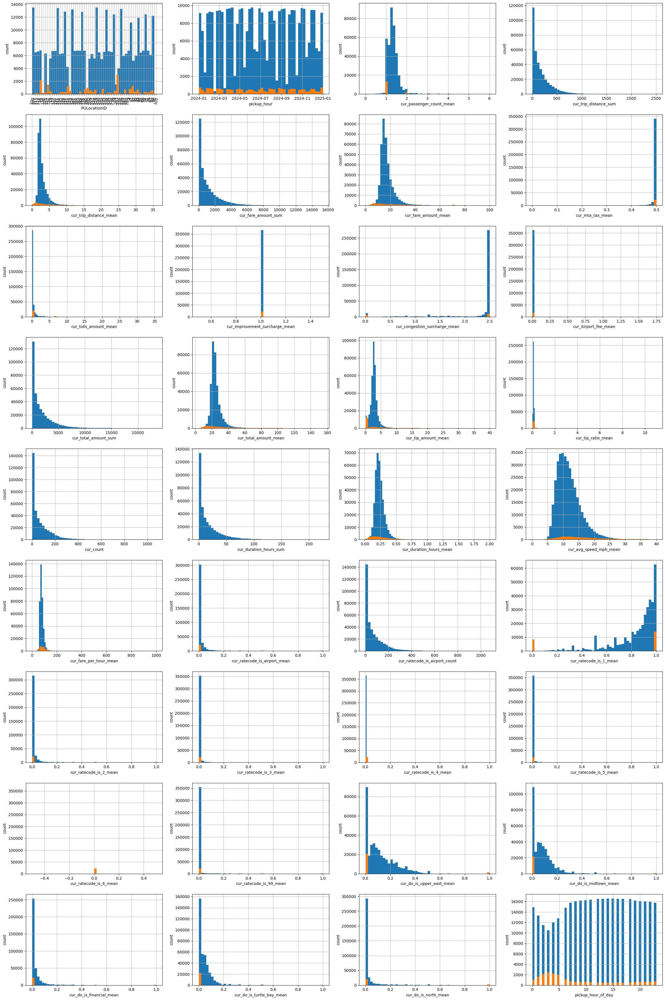

In [34]:
for i, ax in nplots(len(rides_hour.columns), 4):
    rides_hour[rides_hour["cur_count"] > 1][rides_hour.columns[i]].hist(bins=50, ax=ax)
    rides_hour[rides_hour["cur_count"] == 1][rides_hour.columns[i]].hist(bins=50, ax=ax)
    if rides_hour.columns[i] == "PULocationID":
        ax.tick_params("x", rotation=75)
    ax.set_xlabel(rides_hour.columns[i])
    ax.set_ylabel("count")

# `cur_count` lag predictors

* use `cur_count` as it straight-forwardly means demand
* use sums (instead of means) as sums relate to number of trips
* time periods align with daily and weekly patterns from above
  * 1h lag is not used for training but good for understanding
    how time-coherent the target var is

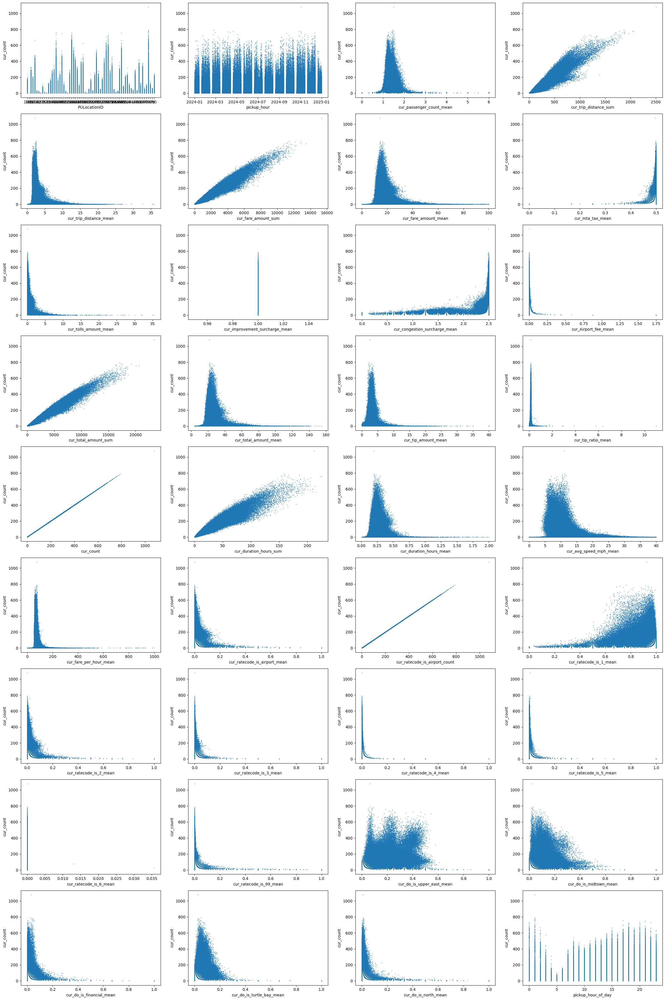

In [35]:
target = "cur_count"

for i, ax in nplots(len(rides_hour.columns), 4):
    sns.scatterplot(
        ax=ax,
        data=rides_hour,
        x=rides_hour.columns[i],
        y=target,
        s=2,
        linewidth=0,
    )
    ax.set_xlabel(rides_hour.columns[i])
    ax.set_ylabel(target)

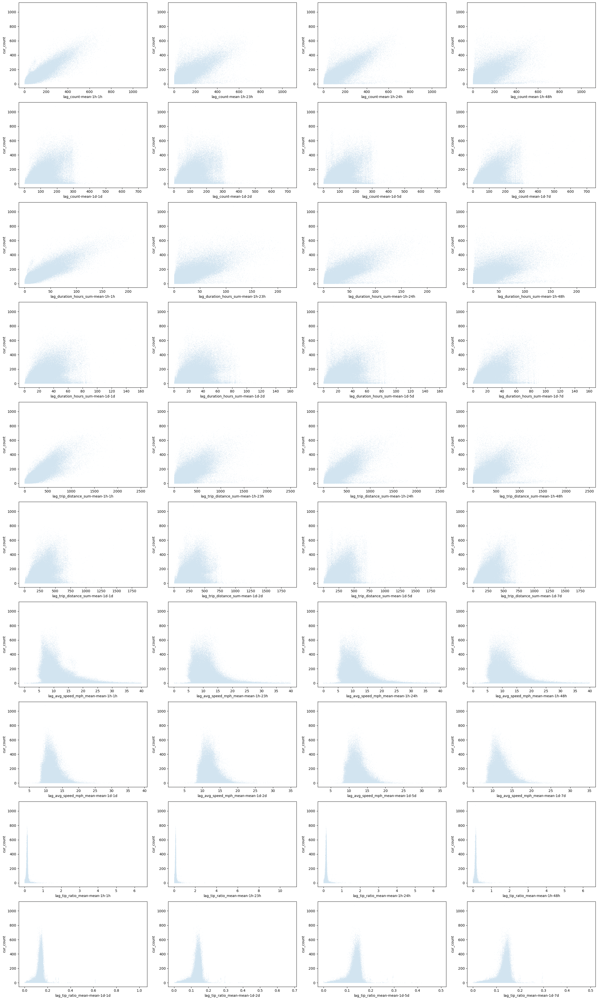

In [36]:
lags = [
    ("count", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("count", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_sum", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("duration_hours_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_sum", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("trip_distance_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    # no linear correlations, but maybe good for correlations in a
    # latent space

    ("avg_speed_mph_mean", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),
]

corrs = dict()

for batch, lag in zip(
    it.batched(nplots(len(lags) * 4, 4), 4),
    lags,
):
    feat, agg, window, offsets = lag
    rides_lag = with_lags(
        rides_hour,
        feat,
        agg,
        window=window,
        offsets=offsets,
    )

    cols_lag = [x for x in rides_lag.columns if x.startswith("lag_")]
    corrs[f"{feat}-{window}"] = list(
        rides_lag[cols_lag].corrwith(rides_lag[target])
    )

    for (_, ax), col in zip(batch, cols_lag):
        sns.scatterplot(
            x=rides_lag[col],
            y=rides_lag[target],
            ax=ax,
            s=0.5,
            linewidth=0,
        )

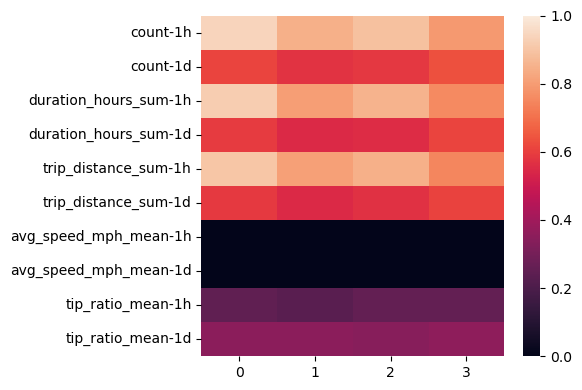

In [37]:
with oneplot(tight=True) as ax:
    sns.heatmap(
        pd.DataFrame(corrs).transpose(),
        vmin=0,
        vmax=1,
    )

# `cur_fare_amount_mean` lag predictors

* targeting mean because this is "the expected return of sending
  and additional cab to a given zone at a given hour
* use means (instead of sums) as the target is a mean
* time periods align with daily and weekly patterns from above
  * 1h lag is not used for training but good for understanding
    how time-coherent the target var is
* relationships here are a lot weaker

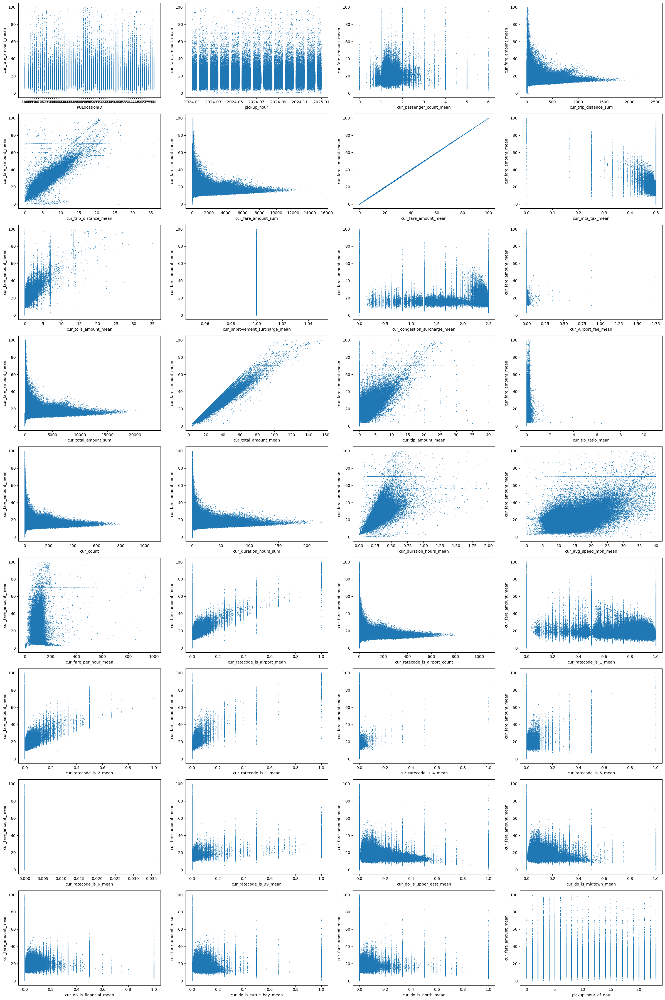

In [38]:
target = "cur_fare_amount_mean"

for i, ax in nplots(len(rides_hour.columns), 4):
    sns.scatterplot(
        ax=ax,
        data=rides_hour,
        x=rides_hour.columns[i],
        y=target,
        s=2,
        linewidth=0,
    )
    ax.set_xlabel(rides_hour.columns[i])
    ax.set_ylabel(target)

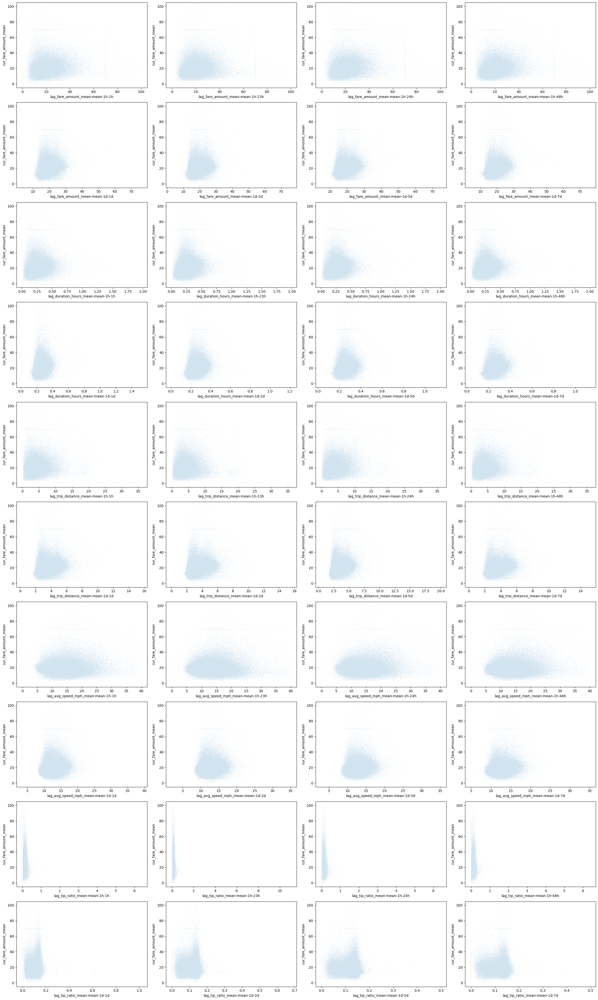

In [39]:
lags = [
    ("fare_amount_mean", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("fare_amount_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_mean", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("duration_hours_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_mean", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("trip_distance_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    # no linear correlations, but maybe good for correlations in a
    # latent space

    ("avg_speed_mph_mean", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["1h", "23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),
]

corrs = dict()

for batch, lag in zip(
    it.batched(nplots(len(lags) * 4, 4), 4),
    lags,
):
    feat, agg, window, offsets = lag
    rides_lag = with_lags(
        rides_hour,
        feat,
        agg,
        window=window,
        offsets=offsets,
    )

    cols_lag = [x for x in rides_lag.columns if x.startswith("lag_")]
    corrs[f"{feat}-{window}"] = list(
        rides_lag[cols_lag].corrwith(rides_lag[target])
    )

    for (_, ax), col in zip(batch, cols_lag):
        sns.scatterplot(
            x=rides_lag[col],
            y=rides_lag[target],
            ax=ax,
            s=0.5,
            linewidth=0,
        )

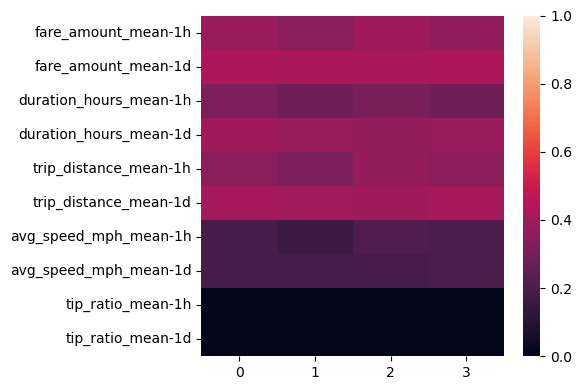

In [40]:
with oneplot(tight=True) as ax:
    sns.heatmap(
        pd.DataFrame(corrs).transpose(),
        vmin=0,
        vmax=1,
    )

# Summary

* use lags for duration and distance
* use lags for avg speed, related to trip duration
* use lags for tip amount, proxy for pickup/drop off
* use lags for zones and
